# Sentiment dataset: Decision Tree

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from models.decision_tree import DecisionTree
from utils.data import load_train
from utils.evaluation import evaluate_model, print_report, get_confusion_matrix

X, y = load_train("sentiment")
X, y = np.asarray(X), np.asarray(y)

# 80% to train on, 20% to validate on
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Validation:", X_val.shape,
      " Classes:", len(np.unique(y)))

Train: (9600, 768)  Validation: (2400, 768)  Classes: 3


## Maximum depth

How many questions the tree may ask in a row. No preprocessing is used: a tree splits one feature at a time, so scaling does not change it.

,max_depth,train_accuracy,val_accuracy,val_macro_f1
0,2,0.452500,0.454167,0.453601
1,4,0.510417,0.502500,0.495330
2,8,0.669167,0.493333,0.491938
3,12,0.803438,0.463750,0.463551
4,16,0.818646,0.463750,0.463814


Kept max_depth = 4


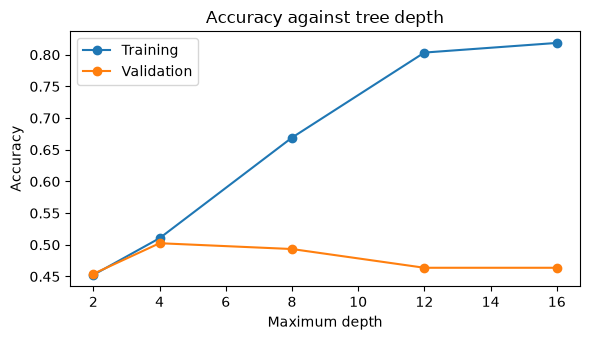

In [2]:
rows = []
best_score = 0

for max_depth in [2, 4, 8, 12, 16]:
    model = DecisionTree(
        max_depth=max_depth, min_samples_split=16, min_samples_leaf=8,
        criterion="gini",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"max_depth": max_depth, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_max_depth = metrics["val_accuracy"], max_depth

depth_table = pd.DataFrame(rows)
display(depth_table)
print("Kept max_depth =", best_max_depth)

plt.figure(figsize=(6, 3.5))
plt.plot(depth_table["max_depth"], depth_table["train_accuracy"], marker="o", label="Training")
plt.plot(depth_table["max_depth"], depth_table["val_accuracy"], marker="o", label="Validation")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Accuracy against tree depth")
plt.legend()
plt.tight_layout()
plt.show()

## Minimum samples to split

A node with fewer examples than this is not split further

In [3]:
rows = []
best_score = 0

for min_samples_split in [2, 32, 128, 512]:
    model = DecisionTree(
        max_depth=best_max_depth, min_samples_split=min_samples_split,
        min_samples_leaf=1, criterion="gini",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"min_samples_split": min_samples_split, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_min_samples_split = metrics["val_accuracy"], min_samples_split

display(pd.DataFrame(rows))
print("Kept min_samples_split =", best_min_samples_split)

,min_samples_split,train_accuracy,val_accuracy,val_macro_f1
0,2,0.510417,0.5025,0.49533
1,32,0.510417,0.5025,0.49533
2,128,0.510417,0.5025,0.49533
3,512,0.510417,0.5025,0.49533


Kept min_samples_split = 2


## Minimum samples in a leaf

Every final group must contain at least this many examples

In [4]:
rows = []
best_score = 0

for min_samples_leaf in [1, 8, 32, 128]:
    model = DecisionTree(
        max_depth=best_max_depth, min_samples_split=best_min_samples_split,
        min_samples_leaf=min_samples_leaf, criterion="gini",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"min_samples_leaf": min_samples_leaf, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_min_samples_leaf = metrics["val_accuracy"], min_samples_leaf

display(pd.DataFrame(rows))
print("Kept min_samples_leaf =", best_min_samples_leaf)

,min_samples_leaf,train_accuracy,val_accuracy,val_macro_f1
0,1,0.510417,0.5025,0.49533
1,8,0.510417,0.5025,0.49533
2,32,0.510417,0.5025,0.49533
3,128,0.510417,0.5025,0.49533


Kept min_samples_leaf = 1


## Splitting criterion

The measure used to pick the best split: Gini impurity or entropy

In [5]:
rows = []
best_score = 0

for criterion in ["gini", "entropy"]:
    model = DecisionTree(
        max_depth=best_max_depth, min_samples_split=best_min_samples_split,
        min_samples_leaf=best_min_samples_leaf, criterion=criterion,
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"criterion": criterion, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_criterion = metrics["val_accuracy"], criterion

display(pd.DataFrame(rows))
print("Kept criterion =", best_criterion)

,criterion,train_accuracy,val_accuracy,val_macro_f1
0,gini,0.510417,0.50250,0.495330
1,entropy,0.500938,0.48375,0.484221


Kept criterion = gini


## Final Model

The hyperparameters we reached and their scores.

In [6]:
print("max_depth:", best_max_depth, " min_samples_split:", best_min_samples_split,
      " min_samples_leaf:", best_min_samples_leaf, " criterion:", best_criterion)

model = DecisionTree(
    max_depth=best_max_depth, min_samples_split=best_min_samples_split,
    min_samples_leaf=best_min_samples_leaf, criterion=best_criterion,
)
model.fit(X_train, y_train)

print(evaluate_model(model, X_train, y_train, X_val, y_val))

val_predictions = model.predict(X_val)
print_report(y_val, val_predictions)

labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, val_predictions, labels=labels)
display(pd.DataFrame(matrix,
                     index=[f"true {label}" for label in labels],
                     columns=[f"predicted {label}" for label in labels]))

max_depth: 4  min_samples_split: 2  min_samples_leaf: 1  criterion: gini
{'train_accuracy': 0.5104166666666666, 'val_accuracy': 0.5025, 'val_macro_f1': 0.49533039070561774}
              precision    recall  f1-score   support

           0       0.53      0.59      0.56       800
           1       0.44      0.33      0.38       800
           2       0.52      0.58      0.55       800

    accuracy                           0.50      2400
   macro avg       0.50      0.50      0.50      2400
weighted avg       0.50      0.50      0.50      2400



,predicted 0,predicted 1,predicted 2
true 0,473,155,172
true 1,274,266,260
true 2,152,181,467


## Underfit, overfit or generalise well?

- **Shallow trees underfit:** at depth 2 to 4, training and validation accuracy are both low.
- **Deep trees overfit:** as depth grows, training accuracy keeps rising while validation accuracy stops improving or falls.
- **No setting generalises well:** the best validation accuracy stays far below the neural network on the same data. A tree splits on one feature at a time, which suits these 768 dense embedding features poorly.